# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [18]:
ROLL_NO = 1024170422          # <-- your full roll number
NAME = "Divakar Purohit"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [19]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [20]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [21]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170422   Name: Divakar Purohit   Fingerprint: B92B674D   Tickets: 14

Ticket_ID                                                                              Ticket_Text
      T01                                              The VPN was working yesterday. Please help.
      T02                    Python is running slowly on my laptop. The same problem occurs again.
      T03                                                            Version 2.0.1 crashes at 99%.
      T04 I couldn't connect to the Wi-Fi when I use mobile hotspot. It works on another computer.
      T05                                              The state-of-the-art lab (Lab-3) is closed.
      T06                                                            Why isn't the portal opening?
      T07                            Laptop was working yesterday on my laptop. Please resolve it.
      T08                             The Matlab crashes while opening. I don't know what changed.
      T09             

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [22]:
rows = []

for _, row in df.iterrows():
    result = process_ticket(row["Ticket_Text"])

    rows.append({
        "Ticket_ID": row["Ticket_ID"],
        "Sentences": len(result["sentences"]),
        "Tokens": len(result["tokens"]),
        "Punctuation tokens": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique tokens": len(set(result["tokens"])),
        "Final tokens": len(result["final"]),
    })

summary_df = pd.DataFrame(rows).set_index("Ticket_ID")
display(summary_df)

summary_df.loc["TOTAL"] = summary_df.sum()
display(summary_df)

,Sentences,Tokens,Punctuation tokens,Stopwords,Unique tokens,Final tokens
Ticket_ID,,,,,,
T01,2,9,2,2,8,5
T02,2,14,2,6,13,6
T03,1,7,2,1,7,4
T04,2,19,2,7,17,10
T05,1,9,3,2,9,4
T06,1,7,1,3,7,3
T07,2,12,2,4,10,6
T08,2,13,2,5,12,6
T09,2,11,2,4,11,5


,Sentences,Tokens,Punctuation tokens,Stopwords,Unique tokens,Final tokens
Ticket_ID,,,,,,
T01,2,9,2,2,8,5
T02,2,14,2,6,13,6
T03,1,7,2,1,7,4
T04,2,19,2,7,17,10
T05,1,9,3,2,9,4
T06,1,7,1,3,7,3
T07,2,12,2,4,10,6
T08,2,13,2,5,12,6
T09,2,11,2,4,11,5


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* In ticket T12 word_tokenize() splits can't into ca and n't. Both fragments remain in the final tokens because neither is a punctuation token or an English stopword in the starters pipeline. ca is a fragment of can, and n't carries the negation.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [34]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

import re

text = df.iloc[0]["Ticket_Text"]
long_words = re.findall(r"\b[A-Za-z]{6,}\b", text)

print(long_words)

number_pattern = r"\b\d+(?:,\d{3})*(?:\.\d+)*\b"

t03_text = df.iloc[2]["Ticket_Text"]
print(re.findall(number_pattern, t03_text))
print(re.findall(number_pattern, TEST_LINES[1]))

capitalized_pattern = r"\b[A-Z][A-Za-z]*\b"
vowel_pattern = r"\b[AEIOUaeiou][A-Za-z]*\b"

t04_text = df.iloc[3]["Ticket_Text"]

print("Capitalized:", re.findall(capitalized_pattern, t04_text))
print("Starts with a vowel:", re.findall(vowel_pattern, t04_text))

email_pattern = r"\b[A-Za-z0-9_+%-]+(?:\.[A-Za-z0-9_+%-]+)*@[A-Za-z0-9-]+(?:\.[A-Za-z0-9-]+)*\.[A-Za-z]{2,}\b"

t13_text = df.iloc[12]["Ticket_Text"]

print(re.sub(email_pattern, "<EMAIL>", t13_text))
print(re.sub(email_pattern, "<EMAIL>", TEST_LINES[0]))

url_pattern = r'\b(?:https?://|www\.)[^\s<>";,]*[A-Za-z0-9/#=&%_~-]'

email_hidden = re.sub(email_pattern, "<EMAIL>", TEST_LINES[0])
url_hidden = re.sub(url_pattern, "<URL>", email_hidden)

print(url_hidden)

phone_pattern = r"(?<!\w)(?:\+91[ -]\d{5}[ -]\d{5}|0\d{3}-\d{3}-\d{4})(?!\w)"

print(re.sub(phone_pattern, "<PHONE>", TEST_LINES[1]))


long_word_pattern = r"\b[A-Za-z]{6,}\b"

def analyze_text(text):
    redacted = re.sub(email_pattern, "<EMAIL>", text)
    redacted = re.sub(url_pattern, "<URL>", redacted)
    redacted = re.sub(phone_pattern, "<PHONE>", redacted)

    return {
        "Words longer than 5 letters": re.findall(long_word_pattern, text),
        "Numbers": re.findall(number_pattern, text),
        "Capitalized words": re.findall(capitalized_pattern, text),
        "Words starting with a vowel": re.findall(vowel_pattern, text),
        "Redacted text": redacted,
    }

results = []

for _, row in df.iterrows():
    results.append({
        "Source": row["Ticket_ID"],
        **analyze_text(row["Ticket_Text"]),
    })

for i, line in enumerate(TEST_LINES, start=1):
    results.append({
        "Source": f"TEST {i}",
        **analyze_text(line),
    })

regex_df = pd.DataFrame(results).set_index("Source")
display(regex_df)

sentence_capitals = []

for text in df["Ticket_Text"]:
    for sentence in process_ticket(text)["sentences"]:
        match = re.match(capitalized_pattern, sentence)
        if match and match.group() not in {"I", "Python"}:
            sentence_capitals.append(match.group())

print(sentence_capitals)
print("Count:", len(sentence_capitals))

['working', 'yesterday', 'Please']
['2.0.1', '99']
['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1,250']
Capitalized: ['I', 'Wi', 'Fi', 'I', 'It']
Starts with a vowel: ['I', 'I', 'use', 'It', 'on', 'another']
Email me at <EMAIL>.
Mail <EMAIL> or <EMAIL>; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>.
Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.


,Words longer than 5 letters,Numbers,Capitalized words,Words starting with a vowel,Redacted text
Source,,,,,
T01,"[working, yesterday, Please]",[],"[The, VPN, Please]",[],The VPN was working yesterday. Please help.
T02,"[Python, running, slowly, laptop, problem, occ...",[],"[Python, The]","[is, on, occurs, again]",Python is running slowly on my laptop. The sam...
T03,"[Version, crashes]","[2.0.1, 99]",[Version],[at],Version 2.0.1 crashes at 99%.
T04,"[couldn, connect, mobile, hotspot, another, co...",[],"[I, Wi, Fi, I, It]","[I, I, use, It, on, another]",I couldn't connect to the Wi-Fi when I use mob...
T05,[closed],[3],"[The, Lab]","[of, art, is]",The state-of-the-art lab (Lab-3) is closed.
T06,"[portal, opening]",[],[Why],"[isn, opening]",Why isn't the portal opening?
T07,"[Laptop, working, yesterday, laptop, Please, r...",[],"[Laptop, Please]","[on, it]",Laptop was working yesterday on my laptop. Ple...
T08,"[Matlab, crashes, opening, changed]",[],"[The, Matlab, I]","[opening, I]",The Matlab crashes while opening. I don't know...
T09,"[projector, failed, another, solution]",[],"[The, Is]","[open, Is, another]",The projector failed to open. Is there another...


['The', 'Please', 'The', 'Version', 'It', 'The', 'Why', 'Laptop', 'Please', 'The', 'The', 'Is', 'The', 'It', 'The', 'It', 'Please', 'Email', 'The']
Count: 19


**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* In my 14 tickets 19 word occurrences are capitalized only because they begin a sentence.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [39]:
from nltk.tokenize import RegexpTokenizer

word_pattern = r"\w+(?:['’-]\w+)*"
word_tokenizer = RegexpTokenizer(word_pattern)

print(word_tokenizer.tokenize(TEST_LINES[2]))

number_word_pattern = number_pattern + "|" + word_pattern
number_word_tokenizer = RegexpTokenizer(number_word_pattern)

print(number_word_tokenizer.tokenize(TEST_LINES[2]))
print(number_word_tokenizer.tokenize(df.iloc[2]["Ticket_Text"]))

token_pattern = "|".join([
    email_pattern,
    url_pattern,
    phone_pattern,
    number_pattern,
    word_pattern,
    r"[^\w\s]",
])

custom_tokenizer = RegexpTokenizer(token_pattern)

def my_tokenize(text):
    return custom_tokenizer.tokenize(text)

print(my_tokenize(TEST_LINES[0]))
print(my_tokenize(TEST_LINES[1]))

t06_text = df.iloc[5]["Ticket_Text"]

print("Raw ticket:", t06_text)
print("NLTK:     ", word_tokenize(t06_text))
print("Custom:   ", my_tokenize(t06_text))

comparison_rows = []

for source, text in [
    *zip(df["Ticket_ID"], df["Ticket_Text"]),
    *((f"TEST {i}", line) for i, line in enumerate(TEST_LINES, start=1)),
]:
    nltk_tokens = word_tokenize(text)
    custom_tokens = my_tokenize(text)

    comparison_rows.append({
        "Source": source,
        "NLTK tokens": nltk_tokens,
        "Custom tokens": custom_tokens,
        "Different": nltk_tokens != custom_tokens,
    })

comparison_df = pd.DataFrame(comparison_rows).set_index("Source")

with pd.option_context("display.max_colwidth", None):
    display(comparison_df)

ticket_differences = comparison_df.loc[df["Ticket_ID"], "Different"]
print("Tickets with different tokenization:", ticket_differences.sum())

['The', 'state-of-the-art', 'lab', "isn't", 'open', 'log-in', 'at', '5', '30', 'p', 'm', "didn't", 'work']
['The', 'state-of-the-art', 'lab', "isn't", 'open', 'log-in', 'at', '5.30', 'p', 'm', "didn't", 'work']
['Version', '2.0.1', 'crashes', 'at', '99']
['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
Raw ticket: Why isn't the portal opening?
NLTK:      ['Why', 'is', "n't", 'the', 'portal', 'opening', '?']
Custom:    ['Why', "isn't", 'the', 'portal', 'opening', '?']


,NLTK tokens,Custom tokens,Different
Source,,,
T01,"[The, VPN, was, working, yesterday, ., Please, help, .]","[The, VPN, was, working, yesterday, ., Please, help, .]",False
T02,"[Python, is, running, slowly, on, my, laptop, ., The, same, problem, occurs, again, .]","[Python, is, running, slowly, on, my, laptop, ., The, same, problem, occurs, again, .]",False
T03,"[Version, 2.0.1, crashes, at, 99, %, .]","[Version, 2.0.1, crashes, at, 99, %, .]",False
T04,"[I, could, n't, connect, to, the, Wi-Fi, when, I, use, mobile, hotspot, ., It, works, on, another, computer, .]","[I, couldn't, connect, to, the, Wi-Fi, when, I, use, mobile, hotspot, ., It, works, on, another, computer, .]",True
T05,"[The, state-of-the-art, lab, (, Lab-3, ), is, closed, .]","[The, state-of-the-art, lab, (, Lab-3, ), is, closed, .]",False
T06,"[Why, is, n't, the, portal, opening, ?]","[Why, isn't, the, portal, opening, ?]",True
T07,"[Laptop, was, working, yesterday, on, my, laptop, ., Please, resolve, it, .]","[Laptop, was, working, yesterday, on, my, laptop, ., Please, resolve, it, .]",False
T08,"[The, Matlab, crashes, while, opening, ., I, do, n't, know, what, changed, .]","[The, Matlab, crashes, while, opening, ., I, don't, know, what, changed, .]",True
T09,"[The, projector, failed, to, open, ., Is, there, another, solution, ?]","[The, projector, failed, to, open, ., Is, there, another, solution, ?]",False


Tickets with different tokenization: 5


**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* okenizers differ on 5 tickets

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [46]:
unique_final_tokens = set()

for text in df["Ticket_Text"]:
    final_tokens = process_ticket(text)["final"]
    unique_final_tokens.update(final_tokens)

unique_final_tokens = sorted(unique_final_tokens)

print("Unique final tokens:", len(unique_final_tokens))
print("First 15:", unique_final_tokens[:15])

from nltk.stem import PorterStemmer, LancasterStemmer

porter = PorterStemmer()
lancaster = LancasterStemmer()

for word in ["working", "worked", "opening", "version"]:
    print(word, ":  Porter:", porter.stem(word),
          "| Lancaster:", lancaster.stem(word))


from nltk.stem import RegexpStemmer

regexp_stemmer = RegexpStemmer(r"ing$", min=5)

for word in ["working", "opening", "running", "worked"]:
    print(word, ":", regexp_stemmer.stem(word))


from nltk import pos_tag
from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()

t02_text = df.iloc[1]["Ticket_Text"]
sentence = process_ticket(t02_text)["sentences"][0]
tagged_tokens = pos_tag(word_tokenize(sentence))

print(tagged_tokens)

print("Default lemma:", lemmatizer.lemmatize("running"))
print("Verb lemma:", lemmatizer.lemmatize("running", pos="v"))

from collections import Counter, defaultdict

tag_counts = defaultdict(Counter)

for text in df["Ticket_Text"]:
    for sentence in process_ticket(text)["sentences"]:
        for token, tag in pos_tag(word_tokenize(sentence)):
            tag_counts[token.lower()][tag] += 1

print("Tags for running:", tag_counts["running"])

pos_map = {"N": "n", "V": "v", "J": "a", "R": "r"}
stem_rows = []

for token in unique_final_tokens:
    tag = tag_counts[token].most_common(1)[0][0]
    wordnet_pos = pos_map.get(tag[0])

    forms = {
        "Porter": porter.stem(token),
        "Lancaster": lancaster.stem(token),
        "Regexp": regexp_stemmer.stem(token),
        "WordNet lemma": (
            lemmatizer.lemmatize(token, pos=wordnet_pos)
            if wordnet_pos else token
        ),
    }

    if len(set(forms.values())) > 1:
        stem_rows.append({"Token": token, "POS tag": tag, **forms})

stem_df = pd.DataFrame(stem_rows).set_index("Token")
display(stem_df)

Unique final tokens: 52
First 15: ['2.0.1', '99', 'another', 'ca', 'changed', 'closed', 'computer', 'connect', 'could', 'crashes', 'email', 'error', 'failed', 'help', 'helpdesk']
working :  Porter: work | Lancaster: work
worked :  Porter: work | Lancaster: work
opening :  Porter: open | Lancaster: op
version :  Porter: version | Lancaster: vert
working : work
opening : open
running : runn
worked : worked
[('Python', 'NNP'), ('is', 'VBZ'), ('running', 'VBG'), ('slowly', 'RB'), ('on', 'IN'), ('my', 'PRP$'), ('laptop', 'NN'), ('.', '.')]
Default lemma: running
Verb lemma: run
Tags for running: Counter({'VBG': 1})


,POS tag,Porter,Lancaster,Regexp,WordNet lemma
Token,,,,,
another,DT,anoth,anoth,another,another
changed,VBD,chang,chang,changed,change
closed,VBN,close,clos,closed,close
computer,NN,comput,comput,computer,computer
crashes,NNS,crash,crash,crashes,crash
error,NN,error,er,error,error
failed,VBD,fail,fail,failed,fail
latest,JJS,latest,latest,latest,late
lms,NNP,lm,lms,lms,lm


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:* Over-stemming: Lancaster reduces version to vert cutting the noun down to an unrecognizable form.
Under-stemming: My ing$ rule reduces working to work but leaves worked unchanged so two forms of the same verb still have different stems.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

S1 — all tokens: 160
S2 — without punctuation: 132
S3 — final tokens: 77
S4 — Porter-stemmed final tokens: 77


,Total tokens,Unique tokens,TTR
Stage,,,
S1,160,78,0.4875
S2,132,72,0.5455
S3,77,52,0.6753
S4,77,49,0.6364


S1  Top 10 tokens


,Token,Count
0,.,22
1,the,13
2,is,7
3,yesterday,4
4,i,4
5,n't,4
6,it,4
7,please,3
8,on,3
9,laptop,3


S3  Top 10 tokens


,Token,Count
0,yesterday,4
1,n't,4
2,please,3
3,laptop,3
4,showing,3
5,error,3
6,working,2
7,help,2
8,python,2
9,problem,2


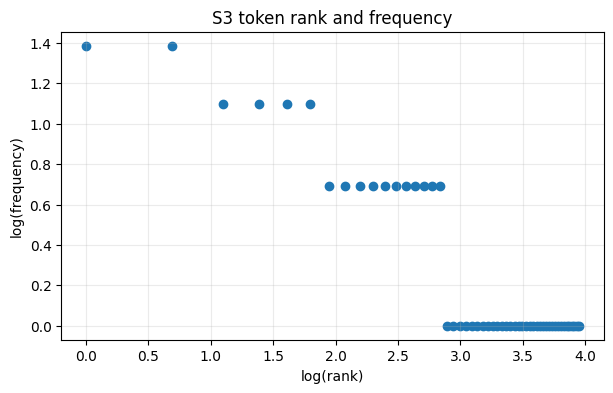

S1 — Top 5 bigrams


,Bigram,Count
0,"(yesterday, .)",3
1,"(., please)",3
2,"(., it)",3
3,"(is, showing)",3
4,"(showing, an)",3


S3 — Top 5 bigrams


,Bigram,Count
0,"(showing, error)",3
1,"(working, yesterday)",2
2,"(please, help)",2
3,"(problem, occurs)",2
4,"(password, showing)",2


In [51]:
s1, s2, s3 = [], [], []

for text in df["Ticket_Text"]:
    result = process_ticket(text)

    s1.extend(result["tokens"])
    s2.extend(token for token in result["tokens"] if not is_punct(token))
    s3.extend(result["final"])

s4 = [porter.stem(token) for token in s3]

print("S1 — all tokens:", len(s1))
print("S2 — without punctuation:", len(s2))
print("S3 — final tokens:", len(s3))
print("S4 — Porter-stemmed final tokens:", len(s4))


stats_rows = []

for stage, tokens in [("S1", s1), ("S2", s2), ("S3", s3), ("S4", s4)]:
    total = len(tokens)
    unique = len(set(tokens))

    stats_rows.append({
        "Stage": stage,
        "Total tokens": total,
        "Unique tokens": unique,
        "TTR": round(unique / total, 4),
    })

stats_df = pd.DataFrame(stats_rows).set_index("Stage")
display(stats_df)

from collections import Counter

s1_freq = Counter(s1)
s3_freq = Counter(s3)

print("S1  Top 10 tokens")
display(pd.DataFrame(s1_freq.most_common(10), columns=["Token", "Count"]))

print("S3  Top 10 tokens")
display(pd.DataFrame(s3_freq.most_common(10), columns=["Token", "Count"]))


from math import log
import matplotlib.pyplot as plt

ranked_tokens = s3_freq.most_common()

log_ranks = [log(rank) for rank in range(1, len(ranked_tokens) + 1)]
log_frequencies = [log(count) for token, count in ranked_tokens]

plt.figure(figsize=(7, 4))
plt.scatter(log_ranks, log_frequencies)
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("S3 token rank and frequency")
plt.grid(alpha=0.25)
plt.show()


from nltk import bigrams

s1_bigram_counts = Counter()
s3_bigram_counts = Counter()

for text in df["Ticket_Text"]:
    result = process_ticket(text)

    s1_bigram_counts.update(bigrams(result["tokens"]))
    s3_bigram_counts.update(bigrams(result["final"]))

print("S1  Top 5 bigrams")
display(pd.DataFrame(
    s1_bigram_counts.most_common(5), columns=["Bigram", "Count"]
))

print("S3  Top 5 bigrams")
display(pd.DataFrame(
    s3_bigram_counts.most_common(5), columns=["Bigram", "Count"]
))

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* TTR rises from 0.4875 in S1 to 0.6753 in S3 because removing repeated punctuation and stopwords reduces the total token count proportionally more than the unique count.

 Porter stemming then merges forms such as working, worked, and works into work. The total stays at 77, but the unique count drops from 52 to 49, lowering TTR to 0.6364 in S4.

6. Interpretation
Answer briefly:

(a) Why does TTR change from S1 to S4 in your dataset?

(b) Give one example where word_tokenize() and your tokenizer differ. Explain the difference.

(c) Give one example where stemming produces an undesirable result.

(d) Give one example where POS-aware lemmatization preserves meaning better than stemming.

(a)
TTR rises from 0.4875 in S1 to 0.6753 in S3 because removing repeated punctuation and stopwords reduces the total token count proportionally more than the unique count.

Porter stemming then merges forms such as working, worked, and works into work. The total stays at 77, but the unique count drops from 52 to 49, lowering TTR to 0.6364 in S4.

(b)
In T06, word_tokenize() splits isn't into is and n't. My tokenizer keeps isn't as one token because its word pattern allows an apostrophe between word characters.

(c)
The ing$ rule turns running into runn.
It removes the suffix and leaves the doubled n producing a fragment.

(d)
In T02, running is tagged VBG in “Python is running slowly.” Using the verb tag, WordNet returns run the base form of the action.
The regex stemmer gives runn.